In [1]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
print(os.listdir("/content/drive/MyDrive"))

In [6]:
import pandas as pd
import re
from pathlib import Path

carpeta = Path("/content/drive/MyDrive/Vacas en establo marzo - junio 2025")  # ajústala

VACAS = [1204, 1221, 1233, 1497, 1554, 1572, 1613, 1624, 1634,
         2072, 2076, 2078, 2082, 6003, 6036, 6178, 6191, 6194,
         6211, 6232, 6238, 8709, 8712, 8729, 8732, 8755, 8758,
         8771, 8775, 8777, 8779, 8782, 8792, 8794]

archivos = {}
for p in carpeta.rglob("*.csv"):
    m = re.search(r"\d{4}", p.stem)
    if m and int(m.group()) in VACAS:
        archivos[int(m.group())] = p

print(f"Encontrados {len(archivos)} de {len(VACAS)} archivos")
faltan = sorted(set(VACAS) - set(archivos))
print("Faltan:", faltan)

Encontrados 34 de 34 archivos
Faltan: []


In [12]:
def leer_vaca(ruta):
    raw = pd.read_csv(ruta, header=None, dtype=str, encoding="utf-8-sig")
    grupos = raw.iloc[0].ffill()
    subs = raw.iloc[1].fillna("").str.strip()

    nombres = []
    for g, s in zip(grupos, subs):
        g = str(g).strip()
        if g == "Main":
            nombres.append(s or g)
        else:
            nombres.append(f"{g} | {s}" if s else g)

    df = raw.iloc[2:].reset_index(drop=True)
    df.columns = nombres

    # Convertir a número lo que se pueda (el resto queda como texto)
    for c in df.columns:
        convertida = pd.to_numeric(df[c].str.replace(",", ".", regex=False),
                                   errors="coerce")
        if convertida.notna().sum() > 0.5 * df[c].notna().sum():
            df[c] = convertida
    return df

# Prueba con una vaca
df = leer_vaca(archivos[1204])
print(df.shape)
print(df.columns.tolist())
df.head(3)

(259, 35)
['Hora de inicio', 'Acción', 'Duración (mm:ss)', 'Producción (kg)', 'Estado | Número de ordeño', 'Estado | RCS (* 1000 células / ml)', 'Estado | Patada', 'Estado | Incompleto', 'Estado | Pezones no encontrados', 'Estado AMD | Ubre', 'Estado AMD | Pezón', 'Media de los flujos (kg/min) | DI', 'Media de los flujos (kg/min) | DD', 'Media de los flujos (kg/min) | TI', 'Media de los flujos (kg/min) | TD', 'Sangre (ppm) | DI', 'Sangre (ppm) | DD', 'Sangre (ppm) | TI', 'Sangre (ppm) | TD', 'Conductividad (mS / cm) | DI', 'Conductividad (mS / cm) | DD', 'Conductividad (mS / cm) | TI', 'Conductividad (mS / cm) | TD', 'Misc | EO/PO', 'Misc | Usuario', 'Misc | Destino Leche', 'Misc | Razón de la desviación', 'Flujos máximos (kg/min) | DI', 'Flujos máximos (kg/min) | DD', 'Flujos máximos (kg/min) | TI', 'Flujos máximos (kg/min) | TD', 'Producciones (kg) | DI', 'Producciones (kg) | DD', 'Producciones (kg) | TI', 'Producciones (kg) | TD']


,Hora de inicio,Acción,Duración (mm:ss),Producción (kg),Estado | Número de ordeño,Estado | RCS (* 1000 células / ml),Estado | Patada,Estado | Incompleto,Estado | Pezones no encontrados,Estado AMD | Ubre,...,Misc | Destino Leche,Misc | Razón de la desviación,Flujos máximos (kg/min) | DI,Flujos máximos (kg/min) | DD,Flujos máximos (kg/min) | TI,Flujos máximos (kg/min) | TD,Producciones (kg) | DI,Producciones (kg) | DD,Producciones (kg) | TI,Producciones (kg) | TD
0,01/03/2025 05:37 a. m.,Ordeño,09:58,23.96,1.0,NaN,NaN,NaN,NaN,1.0,...,Tanque,NaN,1.74,2.16,2.40,2.10,6.11,5.56,3.33,8.96
1,01/03/2025 07:15 p. m.,Ordeño,06:51,17.20,2.0,NaN,DI,NaN,NaN,1.0,...,Tanque,NaN,2.10,2.34,2.52,2.28,3.23,4.86,2.69,6.42
2,02/03/2025 02:24 a. m.,Ordeño,07:23,11.13,1.0,NaN,NaN,NaN,NaN,1.0,...,Tanque,NaN,1.68,1.98,2.34,1.92,4.40,2.43,1.15,3.15


/tmp/ipykernel_11441/848290468.py:41: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  todas = pd.concat(dfs.values(), ignore_index=True)


Filas totales: 7249
Fechas no legibles: 0
Valores de 'Acción': {'Ordeño': 7016, 'Rechazada': 172, 'Echada sin ordeñar': 61}
Esquemas de columnas distintos: 1
Filas duplicadas: 25
Columnas vacías en TODAS las vacas: ['Estado | RCS (* 1000 células / ml)', 'Misc | Usuario']

--- VERIFICACIONES DE DUPLICADOS ---
49 filas involucradas | duplicados exactos: 4
      vaca          Hora de inicio              Acción  Producción (kg)  \
449   1233  16/03/2025 06:23 a. m.              Ordeño            14.54   
450   1233  16/03/2025 06:23 a. m.  Echada sin ordeñar              NaN   
541   1233  06/05/2025 02:46 p. m.           Rechazada              NaN   
542   1233  06/05/2025 02:46 p. m.           Rechazada              NaN   
1030  1572  16/03/2025 03:03 a. m.  Echada sin ordeñar              NaN   
1031  1572  16/03/2025 03:03 a. m.              Ordeño            12.16   
1229  1613  16/03/2025 05:35 a. m.              Ordeño            13.87   
1230  1613  16/03/2025 05:35 a. m.  Echada s

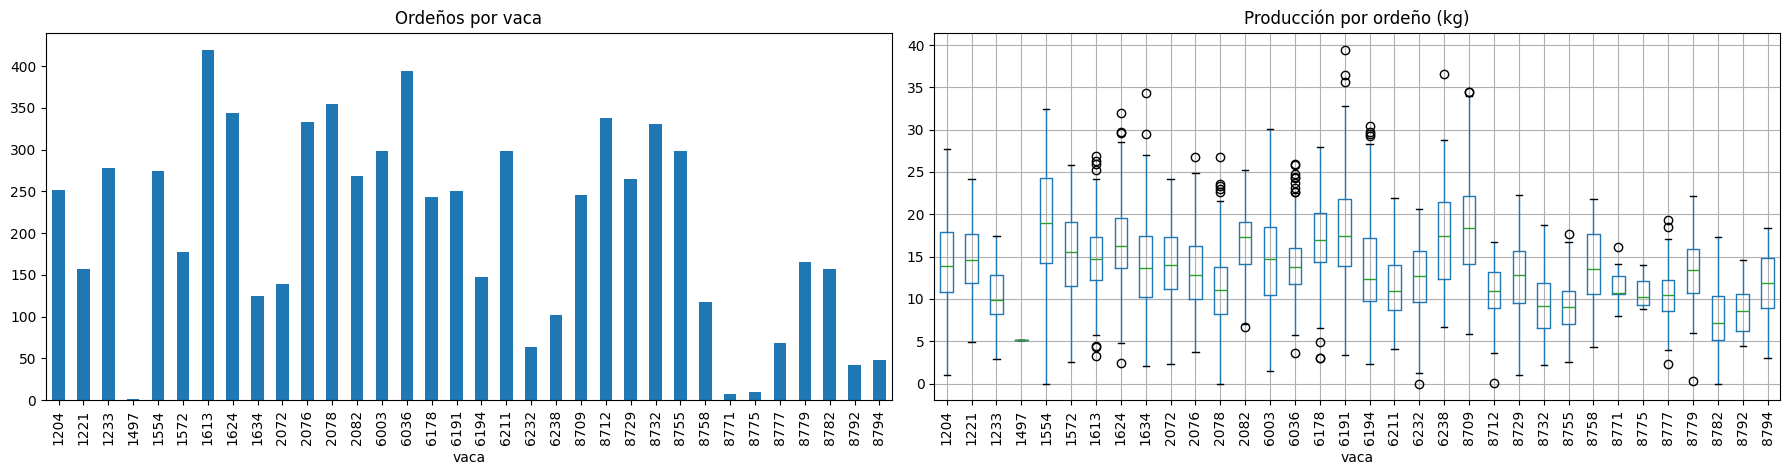

,vaca,ordeños,inicio,fin,días_calendario,días_con_datos,cobertura_%,ordeños_por_día,intervalo_mediano_h,huecos_>48h,...,prod_diaria_kg,patada_%,incompleto_%,pezones_no_enc_%,leche_a_tanque_%,columnas_vacías,nulos_%,Echada sin ordeñar,Ordeño,Rechazada
0,1204,252,2025-03-01,2025-07-18,140,139,99.29,1.81,12.47,0,...,26.46,6.75,11.11,7.14,100.00,3,18.00,0,252,7
1,1221,157,2025-03-01,2025-07-18,140,64,45.71,2.45,8.69,1,...,35.99,14.01,3.82,3.18,92.36,3,18.25,1,157,4
2,1233,278,2025-03-01,2025-07-18,140,138,98.57,2.01,10.73,1,...,20.99,33.09,19.42,44.24,100.00,3,15.84,1,278,17
3,1497,1,2025-07-18,2025-07-18,1,1,100.00,1.00,NaN,0,...,5.20,0.00,0.00,0.00,0.00,7,18.92,1,1,0
4,1554,275,2025-03-01,2025-07-18,140,115,82.14,2.39,9.63,1,...,45.07,11.27,14.55,12.36,100.00,3,17.56,2,275,1
5,1572,177,2025-03-01,2025-07-18,140,86,61.43,2.06,11.47,1,...,31.64,7.91,1.69,1.69,93.79,3,18.46,1,177,8
6,1613,419,2025-03-01,2025-07-18,140,140,100.00,2.99,7.76,0,...,44.78,24.34,3.82,2.63,100.00,4,18.09,1,419,1
7,1624,344,2025-03-01,2025-07-18,140,140,100.00,2.46,9.23,0,...,41.73,8.72,3.20,3.20,100.00,3,18.47,2,344,5
8,1634,125,2025-03-01,2025-07-18,140,53,37.86,2.36,8.92,1,...,33.24,12.00,20.00,24.80,100.00,3,17.30,2,125,5
9,2072,139,2025-03-01,2025-07-18,140,72,51.43,1.93,11.96,2,...,27.81,25.90,5.04,5.04,91.37,3,17.81,3,139,2


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CUARTOS = ["DI", "DD", "TI", "TD"]
UMBRAL_COND = 6.0  # mS/cm (el que usaste en tu reporte)

num = lambda s: pd.to_numeric(s, errors="coerce")

def parsear_fecha(serie):
    s = (serie.astype(str)
         .str.replace("\u202f", " ", regex=False)
         .str.replace("\xa0", " ", regex=False)
         .str.replace(r"a\.\s*m\.", "AM", regex=True)
         .str.replace(r"p\.\s*m\.", "PM", regex=True)
         .str.strip())
    return pd.to_datetime(s, format="%d/%m/%Y %I:%M %p", errors="coerce")

def mmss_a_seg(x):
    if pd.isna(x):
        return np.nan
    try:
        p = [float(i) for i in str(x).split(":")]
    except ValueError:
        return np.nan
    if len(p) == 2: return p[0] * 60 + p[1]
    if len(p) == 3: return p[0] * 3600 + p[1] * 60 + p[2]
    return np.nan

# ---------- 1. Cargar todas las vacas ----------
dfs = {}
for vaca, ruta in sorted(archivos.items()):
    d = leer_vaca(ruta)
    d["fecha"] = parsear_fecha(d["Hora de inicio"])
    d["dur_s"] = d["Duración (mm:ss)"].map(mmss_a_seg)
    d["Producción (kg)"] = num(d["Producción (kg)"])
    d = d.sort_values("fecha").reset_index(drop=True)
    d.insert(0, "vaca", vaca)
    dfs[vaca] = d

todas = pd.concat(dfs.values(), ignore_index=True)

# ---------- 2. Verificaciones ----------
print("Filas totales:", len(todas))
print("Fechas no legibles:", todas["fecha"].isna().sum())
print("Valores de 'Acción':", todas["Acción"].value_counts(dropna=False).to_dict())
print("Esquemas de columnas distintos:", len({tuple(d.columns) for d in dfs.values()}))
print("Filas duplicadas:", todas.duplicated(subset=["vaca", "Hora de inicio"]).sum())

# ---------- 3. Resumen por vaca ----------
def resumir(d):
    f = d["fecha"]
    n = len(d)
    dias = f.dt.normalize().nunique()
    span = (f.max().normalize() - f.min().normalize()).days + 1
    inter_h = f.diff().dt.total_seconds() / 3600
    prod = d["Producción (kg)"]
    r = {
        "vaca": d["vaca"].iloc[0] if "vaca" in d.columns else np.nan,
        "ordeños": n,
        "inicio": f.min().date(),
        "fin": f.max().date(),
        "días_calendario": span,
        "días_con_datos": dias,
        "cobertura_%": (dias / span * 100) if span > 0 else np.nan,
        "ordeños_por_día": (n / dias) if dias > 0 else np.nan,
        "intervalo_mediano_h": inter_h.median(),
        "huecos_>48h": int((inter_h > 48).sum()),
        "hueco_max_días": (inter_h.max() / 24) if len(inter_h) > 1 else np.nan,
        "cobertura_ventana_%": (dias / 140 * 100),
        "datos_suficientes": n >= 30,
        "dur_media_min": d["dur_s"].mean() / 60,
        "prod_media_kg": prod.mean(),
        "prod_std_kg": prod.std(),
        "prod_min_kg": prod.min(),
        "prod_max_kg": prod.max(),
        "prod_diaria_kg": (prod.sum() / dias) if dias > 0 else np.nan,
    }
    for col, nombre in [("Estado | Patada", "patada"),
                        ("Estado | Incompleto", "incompleto"),
                        ("Estado | Pezones no encontrados", "pezones_no_enc")]:
        r[f"{nombre}_%"] = d[col].notna().mean() * 100
    dest = d["Misc | Destino Leche"]
    r["leche_a_tanque_%"] = ((dest == "Tanque").sum() / dest.notna().sum() * 100
                             if dest.notna().any() else np.nan)
    sin_vaca = d.drop(columns="vaca", errors="ignore")
    r["columnas_vacías"] = int(sin_vaca.isna().all().sum())
    r["nulos_%"] = sin_vaca.isna().mean().mean() * 100
    return r

def resumir_cuartos(d):
    filas = []
    for q in CUARTOS:
        cond = num(d[f"Conductividad (mS / cm) | {q}"])
        sang = num(d[f"Sangre (ppm) | {q}"])
        filas.append({
            "vaca": d["vaca"].iloc[0],
            "cuarto": q,
            "prod_media_kg": num(d[f"Producciones (kg) | {q}"]).mean(),
            "flujo_medio": num(d[f"Media de los flujos (kg/min) | {q}"]).mean(),
            "flujo_max": num(d[f"Flujos máximos (kg/min) | {q}"]).mean(),
            "cond_media": cond.mean(),
            f"cond_>{UMBRAL_COND}_%": (cond > UMBRAL_COND).mean() * 100,
            "sangre_>0_n": int((sang > 0).sum()),
        })
    return filas

# Solo ordeños para todas las estadísticas
dfs_ord = {v: d[d["Acción"] == "Ordeño"].reset_index(drop=True) for v, d in dfs.items()}

acciones = pd.crosstab(todas["vaca"], todas["Acción"])
resumen = pd.DataFrame([resumir(d) for d in dfs_ord.values() if len(d) > 0]).round(2)
resumen = resumen.merge(acciones, left_on="vaca", right_index=True, how="left")
cuartos = pd.DataFrame([f for d in dfs_ord.values() if len(d) > 0
                        for f in resumir_cuartos(d)]).round(2)
nulos = pd.DataFrame({v: d.drop(columns="vaca", errors="ignore").isna().mean() * 100
                      for v, d in dfs_ord.items() if len(d) > 0}).T.round(1)

vacias_en_todas = nulos.columns[(nulos == 100).all()].tolist()
print("Columnas vacías en TODAS las vacas:", vacias_en_todas)

# ---------- 6. Tablas globales para el reporte ----------
global_vacas = (resumen.drop(columns=["vaca", "inicio", "fin"], errors="ignore")
                .describe().T[["mean", "std", "min", "50%", "max"]].round(2))
global_cuartos = (cuartos.drop(columns="vaca", errors="ignore").groupby("cuarto").mean().round(2))

# ---------- 7. Verificaciones Extra Solicitadas ----------
print("\n--- VERIFICACIONES DE DUPLICADOS ---")
dup = todas[todas.duplicated(subset=["vaca", "Hora de inicio"], keep=False)].sort_values(["vaca", "fecha"])
print(len(dup), "filas involucradas | duplicados exactos:", todas.duplicated(keep=False).sum())
print(dup[["vaca", "Hora de inicio", "Acción", "Producción (kg)", "Estado | Número de ordeño"]].head(20))

print("\n--- INCIDENTES VS ACCIONES ---")
for c in ["Estado | Patada", "Estado | Incompleto", "Estado | Pezones no encontrados"]:
    print(f"\n{c}:")
    print(pd.crosstab(todas["Acción"], todas[c].notna(), normalize="index").mul(100).round(1))

print("\n--- INCIDENTES POR CUARTO SEPARANDO MULTIPLES ---")
for c in ["Estado | Patada", "Estado | Incompleto", "Estado | Pezones no encontrados", "Estado AMD | Pezón"]:
    ev = todas.loc[todas["Acción"] == "Ordeño", c].dropna().astype(str).str.split(",").explode().str.strip()
    print(f"\n{c}:")
    print(ev.value_counts())

print("\n--- DESTINO LECHE POR VACA (6003, 8771, 8775, 1497) ---")
print(pd.crosstab(todas["vaca"], todas["Misc | Destino Leche"]).loc[[6003, 8771, 8775, 1497], :])

print("\n--- COLUMNAS VACÍAS EN VACAS CRÍTICAS (6211, 6232, 1497) ---")
x = nulos.loc[[6211, 6232, 1497]].T
print(x[(x > 50).any(axis=1)])

# ---------- 8. Gráficas ----------
fig, ax = plt.subplots(1, 2, figsize=(18, 5))
resumen.set_index("vaca")["ordeños"].plot.bar(ax=ax[0], title="Ordeños por vaca")
todas.boxplot(column="Producción (kg)", by="vaca", ax=ax[1], rot=90)
ax[1].set_title("Producción por ordeño (kg)")
plt.suptitle("")
plt.tight_layout()
plt.show()

# ---------- 9. Exportar ----------
with pd.ExcelWriter("resumen_vacas.xlsx") as w:
    resumen.to_excel(w, sheet_name="por_vaca", index=False)
    cuartos.to_excel(w, sheet_name="por_cuarto", index=False)
    global_vacas.to_excel(w, sheet_name="global_vacas")
    global_cuartos.to_excel(w, sheet_name="global_cuartos")
    nulos.to_excel(w, sheet_name="nulos_%")

resumen

In [17]:
from google.colab import files

# Descargar el archivo generado
files.download('resumen_vacas.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>